# EE5130: Artificial Intelligence and Machine Learning
## Hands-On Demonstration (Part 1): Neural Network Foundations, Hyperparameter Engineering, and Convolutional Neural Networks (CNN)

---
### 🎯 Session Objectives & Syllabus Mapping
This hands-on module directly addresses the curriculum for **EE5130 (AIML)**:
- **Module 3: Supervised Learning & Artificial Neural Networks (ANN)**
  - Nonlinear feature space mapping challenges & Perceptrons vs. Multi-Layer Perceptrons (MLP).
  - Activation functions, gradients, and Universal Approximation Theorem.
  - Overfitting and Regularization (Weight decay $L_2$, Dropout, Early Stopping).
- **Module 5: Deep Learning & Practical Implementation**
  - Convolutional Neural Networks (CNN): Kernels, Strides, Padding, Pooling, Receptive Fields.
  - Practical deep learning workflows: Tensor datasets, batching, loss functions, optimizers, learning rates.
  - Live training loop (`zero_grad`, forward, backward, step) and validation loop (`eval`, `no_grad`).
  - Diagnostic metrics: Loss/Accuracy curves, Confusion Matrix, Feature map visualization.
- **Module 12: Emerging Trends in Machine Learning**
  - Transfer Learning: Feature extraction vs. fine-tuning on pretrained vision models.

**Intended Learning Outcomes (ILO):**
- **LO1**: Explain fundamental deep learning concepts, issues (vanishing gradients, overfitting), and trade-offs.
- **LO2**: Formalize a computer vision task into an end-to-end deep learning pipeline.
- **LO3**: Analyze strengths and weaknesses of CNN vs. standard MLP architectures.
- **LO4**: Design, tune, train, validate, and interpret deep neural network models using PyTorch.

---
### ⏱️ Suggested Demonstration Timeline (Total: ~35 Mins)
1. **00:00 - 05:00**: Non-linear feature spaces, Perceptron limitation (XOR), and Activation function dynamics.
2. **05:00 - 12:00**: CNN Mechanics: Convolutions, kernels, padding, pooling, and spatial invariance.
3. **12:00 - 18:00**: Dissecting Hyperparameters: Learning rate ($lpha$), Optimizers (SGD vs Adam), Batch Size, and Regularization ($L_2$, Dropout).
4. **18:00 - 25:00**: Live Training & Validation on Fashion-MNIST: The canonical PyTorch loop in action.
5. **25:00 - 30:00**: Live Experiment: Overfitting vs Regularization (demonstrating the generalization gap).
6. **30:00 - 35:00**: Model Evaluation, Confusion Matrix Heatmap, Feature Map Interpretability, and Transfer Learning touchpoint.


In [1]:
# 1. Core Framework and Environment Setup
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset, random_split
import torchvision
from torchvision import datasets, transforms, models

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
import time
import random
import os

# Set global random seed for exact scientific reproducibility
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(42)

# Hardware acceleration check (GPU vs CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"🚀 PyTorch Version: {torch.__version__}")
print(f"⚙️ Execution Device: {device} " + (f"({torch.cuda.get_device_name(0)})" if torch.cuda.is_available() else "[CPU Mode]"))

# Matplotlib aesthetic configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 11
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12


🚀 PyTorch Version: 2.14.1+cpu
⚙️ Execution Device: cpu [CPU Mode]


---
## Section 1: The Challenge of Mapping Non-Linear Feature Spaces & The Perceptron (Module 3)

### 1.1 The Single-Layer Perceptron & Linear Separability
The Rosenblatt Perceptron computes a linear combination of input features:
$$\hat{y} = f\left(\sum_{i=1}^n w_i x_i + b\right) = f(\mathbf{w}^T \mathbf{x} + b)$$
where $f$ is a step activation function. The decision boundary is the hyperplane $\mathbf{w}^T \mathbf{x} + b = 0$.

> **The Historical Crisis (Minsky & Papert, 1969):** A single-layer perceptron **cannot** solve problems where classes are not linearly separable, most famously the **XOR (Exclusive-OR) logic gate**.

### 1.2 Multi-Layer Perceptrons (MLP) & Universal Approximation
By stacking hidden layers with **non-linear activation functions**, MLPs warp and fold the input feature space into a representation space where classes become linearly separable:
$$\mathbf{h} = \sigma(\mathbf{W}_1 \mathbf{x} + \mathbf{b}_1), \quad \hat{\mathbf{y}} = g(\mathbf{W}_2 \mathbf{h} + \mathbf{b}_2)$$

### 1.3 Activation Functions & Vanishing Gradients
1. **Sigmoid:** $\sigma(z) = \frac{1}{1 + e^{-z}} \implies \sigma'(z) = \sigma(z)(1 - \sigma(z))$. Maximum derivative is $0.25$. As $|z| > 4$, $\sigma'(z) \to 0$. In deep networks, repeated multiplication of small derivatives causes **vanishing gradients**.
2. **Tanh:** $\tanh(z) = \frac{e^z - e^{-z}}{e^z + e^{-z}}$. Zero-centered, max derivative is $1.0$, but still saturates at extreme values.
3. **ReLU (Rectified Linear Unit):** $\text{ReLU}(z) = \max(0, z)$. Derivative is $1.0$ for $z > 0$. Computationally cheap and does not saturate for positive inputs, enabling deep networks.
4. **Leaky ReLU:** $\text{LeakyReLU}(z) = \max(\alpha z, z)$ (with $\alpha \approx 0.01$) to prevent "dying ReLU" neurons.


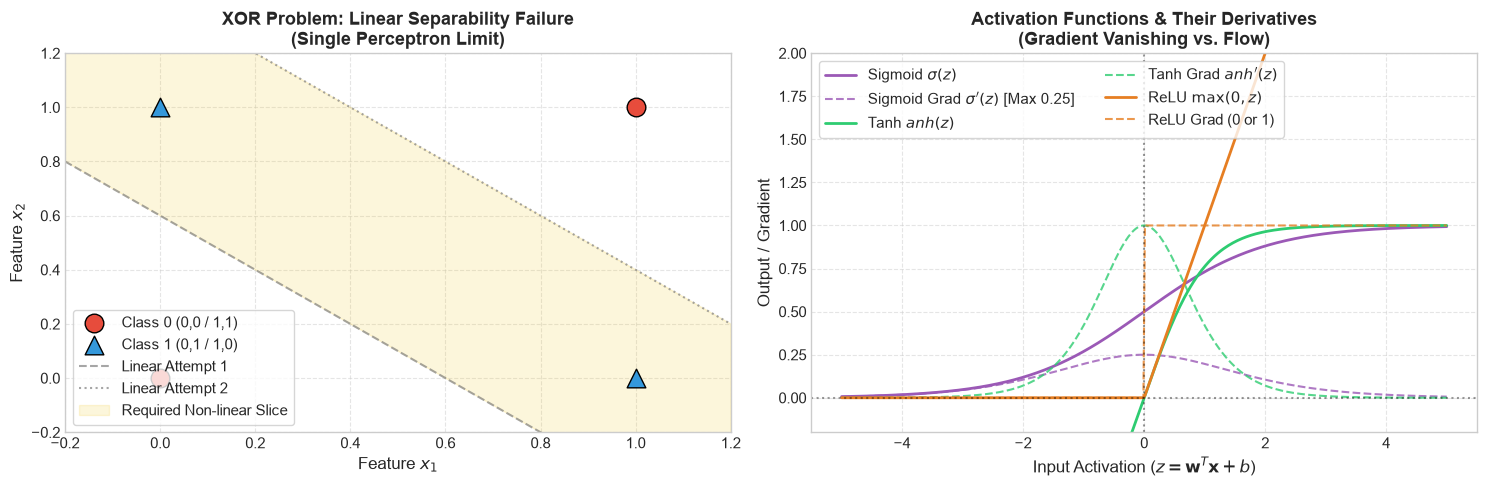

In [2]:
# Visualizing the XOR Non-linear Limitation and Activation Function Gradients
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: XOR Feature Space
X_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y_xor = np.array([0, 1, 1, 0])

ax1.scatter(X_xor[y_xor==0, 0], X_xor[y_xor==0, 1], color='#e74c3c', s=180, edgecolors='black', label='Class 0 (0,0 / 1,1)', zorder=5)
ax1.scatter(X_xor[y_xor==1, 0], X_xor[y_xor==1, 1], color='#3498db', s=180, edgecolors='black', marker='^', label='Class 1 (0,1 / 1,0)', zorder=5)

# Illustrate failed linear boundary attempts
x_line = np.linspace(-0.2, 1.2, 100)
ax1.plot(x_line, -x_line + 0.6, '--', color='gray', alpha=0.7, label='Linear Attempt 1')
ax1.plot(x_line, -x_line + 1.4, ':', color='gray', alpha=0.7, label='Linear Attempt 2')
ax1.fill_between(x_line, -x_line + 0.6, -x_line + 1.4, color='#f1c40f', alpha=0.15, label='Required Non-linear Slice')

ax1.set_xlim(-0.2, 1.2)
ax1.set_ylim(-0.2, 1.2)
ax1.set_title('XOR Problem: Linear Separability Failure\n(Single Perceptron Limit)', fontweight='bold')
ax1.set_xlabel('Feature $x_1$')
ax1.set_ylabel('Feature $x_2$')
ax1.legend(loc='lower left', frameon=True)
ax1.grid(True, linestyle='--', alpha=0.5)

# Plot 2: Activation Functions and Derivative Saturation
z = np.linspace(-5, 5, 400)
sigmoid = 1 / (1 + np.exp(-z))
sigmoid_grad = sigmoid * (1 - sigmoid)
tanh = np.tanh(z)
tanh_grad = 1 - tanh**2
relu = np.maximum(0, z)
relu_grad = (z > 0).astype(float)

ax2.plot(z, sigmoid, label='Sigmoid $\sigma(z)$', color='#9b59b6', linewidth=2)
ax2.plot(z, sigmoid_grad, '--', label="Sigmoid Grad $\sigma'(z)$ [Max 0.25]", color='#9b59b6', alpha=0.8)
ax2.plot(z, tanh, label='Tanh $\tanh(z)$', color='#2ecc71', linewidth=2)
ax2.plot(z, tanh_grad, '--', label="Tanh Grad $\tanh'(z)$", color='#2ecc71', alpha=0.8)
ax2.plot(z, relu, label='ReLU $\max(0, z)$', color='#e67e22', linewidth=2)
ax2.plot(z, relu_grad, '--', label="ReLU Grad (0 or 1)", color='#e67e22', alpha=0.8)

ax2.axvline(0, color='black', linestyle=':', alpha=0.4)
ax2.axhline(0, color='black', linestyle=':', alpha=0.4)
ax2.set_title('Activation Functions & Their Derivatives\n(Gradient Vanishing vs. Flow)', fontweight='bold')
ax2.set_xlabel('Input Activation ($z = \mathbf{w}^T \mathbf{x} + b$)')
ax2.set_ylabel('Output / Gradient')
ax2.set_ylim(-0.2, 2.0)
ax2.legend(loc='upper left', ncol=2, frameon=True)
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


---
## Section 2: Convolutional Neural Networks (CNN) Architecture & Theory (Module 5)

### 2.1 Why MLPs Fail on Image Data
Consider a $28 \times 28$ grayscale image:
1. **Loss of 2D Topology:** Flattening $28 \times 28 \to 784$ discards vertical spatial relationships between adjacent pixels.
2. **Explosive Parameter Count:** For a modest $256 \times 256 \times 3$ image connected to a 512-neuron hidden layer, an MLP requires:
   $$256 \times 256 \times 3 \times 512 \approx 100,663,296 \text{ weights!}$$
   This leads directly to massive overfitting and excessive memory requirements.

### 2.2 The Three Fundamental Principles of CNNs
1. **Local Receptive Fields:** Neurons in convolutional layers extract features only from a local window ($K \times K$).
2. **Weight Sharing (Parameter Sharing):** The same kernel/filter slides across the entire image. A $3 \times 3$ filter has only **9 trainable weights + 1 bias**, irrespective of image size!
3. **Translation Invariance:** A feature learned in the top-left corner (e.g., edge, loop) can be recognized anywhere in the image.

### 2.3 The Mathematical Convolution Operation
For a 2D input image $I$ and a filter kernel $K$ of size $k_h \times k_w$:
$$S(i, j) = (I * K)(i, j) = \sum_{m=0}^{k_h-1} \sum_{n=0}^{k_w-1} I(i + m, j + n) K(m, n)$$

**Output Spatial Dimension Formula:**
Given input spatial dimension $W_{in}$, kernel size $K$, padding $P$, and stride $S$:
$$W_{out} = \left\lfloor \frac{W_{in} - K + 2P}{S} \right\rfloor + 1$$

### 2.4 Pooling Mechanisms (Subsampling)
- **Max Pooling:** Takes the maximum value within a $2 \times 2$ window with stride 2. Preserves the most salient activated features while halving spatial resolution ($W/2, H/2$) and providing invariance to small spatial shifts.
- **Average Pooling:** Computes average value; smoother but less contrastive than Max Pooling.


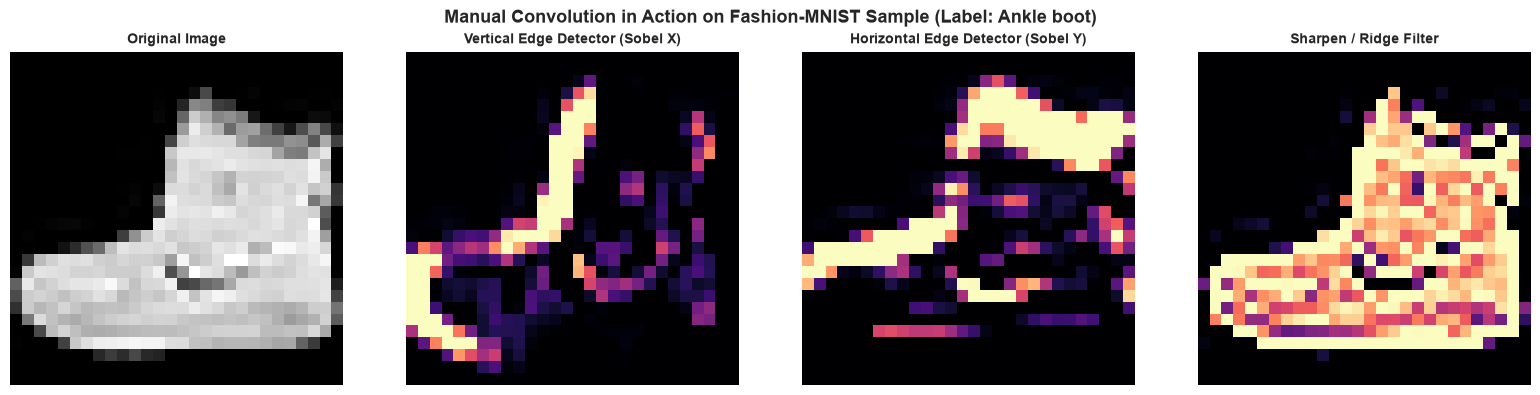

In [3]:
# Demonstration: How Convolutional Filters Extract Spatial Features
# Loading a sample image directly from FashionMNIST
raw_sample_dataset = datasets.FashionMNIST(root='./data', train=True, download=True)
sample_img, sample_label = raw_sample_dataset[0]  # Ankle boot
img_np = np.array(sample_img, dtype=np.float32) / 255.0

# Define classical 3x3 Convolutional Kernels
kernels = {
    "Original Image": None,
    "Vertical Edge Detector (Sobel X)": np.array([[-1, 0, 1],
                                                  [-2, 0, 2],
                                                  [-1, 0, 1]], dtype=np.float32),
    "Horizontal Edge Detector (Sobel Y)": np.array([[-1, -2, -1],
                                                    [ 0,  0,  0],
                                                    [ 1,  2,  1]], dtype=np.float32),
    "Sharpen / Ridge Filter": np.array([[ 0, -1,  0],
                                        [-1,  5, -1],
                                        [ 0, -1,  0]], dtype=np.float32)
}

# 2D Cross-Correlation Function
def apply_2d_conv(image, kernel):
    k_h, k_w = kernel.shape
    pad_h, pad_w = k_h // 2, k_w // 2
    padded = np.pad(image, ((pad_h, pad_h), (pad_w, pad_w)), mode='edge')
    out = np.zeros_like(image)
    for i in range(image.shape[0]):
        for j in range(image.shape[1]):
            window = padded[i:i+k_h, j:j+k_w]
            out[i, j] = np.sum(window * kernel)
    return out

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, (title, k) in zip(axes, kernels.items()):
    if k is None:
        ax.imshow(img_np, cmap='gray')
    else:
        filtered = apply_2d_conv(img_np, k)
        ax.imshow(np.clip(filtered, 0, 1), cmap='magma')
    ax.set_title(title, fontsize=10, fontweight='bold')
    ax.axis('off')

plt.suptitle(f'Manual Convolution in Action on Fashion-MNIST Sample (Label: {raw_sample_dataset.classes[sample_label]})', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


---
## Section 3: Dissecting Hyperparameters & Parameter Setting (Practical Deep Learning)

In deep learning practice, model success depends critically on setting hyperparameters methodically:

| Hyperparameter | Symbol / Typical Value | Physical Role & Impact | Danger of Incorrect Setting |
| :--- | :--- | :--- | :--- |
| **Learning Rate** | $\alpha \in [10^{-4}, 10^{-2}]$ | Step size taken in parameter space along the negative gradient. | **Too High:** Loss explodes/oscillates (divergence).<br>**Too Low:** Stalled training, trapped in poor saddle points. |
| **Batch Size** | $B \in [32, 128]$ | Number of training examples per gradient update step. | **Too Small:** Noisy gradients, slow epoch time.<br>**Too Large:** High memory, sharp minima (poor generalization). |
| **Weight Decay ($L_2$)** | $\lambda \in [10^{-5}, 10^{-2}]$ | Penalizes large weights: $\mathcal{L}_{reg} = \mathcal{L} + \frac{\lambda}{2} \sum \|w\|^2$. | **Zero:** Overfitting and exploding weights.<br>**Too High:** Underfitting (network over-constrained). |
| **Dropout Rate** | $p \in [0.2, 0.5]$ | Probability of zeroing activations during training forward pass. | Prevents neuron co-adaptation; ensembles sub-networks. |
| **Optimizer** | Adam, SGD+Momentum | Update rule incorporating first/second moment statistics. | Adam adapts learning rate per parameter; SGD generalizes well with tuning. |

### The Adam Optimizer Update Rules:
$$m_t = \beta_1 m_{t-1} + (1 - \beta_1) g_t \quad \text{(First moment: moving average of gradient)}$$
$$v_t = \beta_2 v_{t-1} + (1 - \beta_2) g_t^2 \quad \text{(Second moment: moving average of squared gradient)}$$
$$\hat{m}_t = \frac{m_t}{1 - \beta_1^t}, \quad \hat{v}_t = \frac{v_t}{1 - \beta_2^t} \quad \text{(Bias corrections)}$$
$$\theta_{t+1} = \theta_t - \frac{\alpha}{\sqrt{\hat{v}_t} + \epsilon} \hat{m}_t$$


📦 Dataset Partitions Ready:
   Train samples:      8,000
   Validation samples: 2,000
   Test samples:       10,000
   Classes (10):       ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


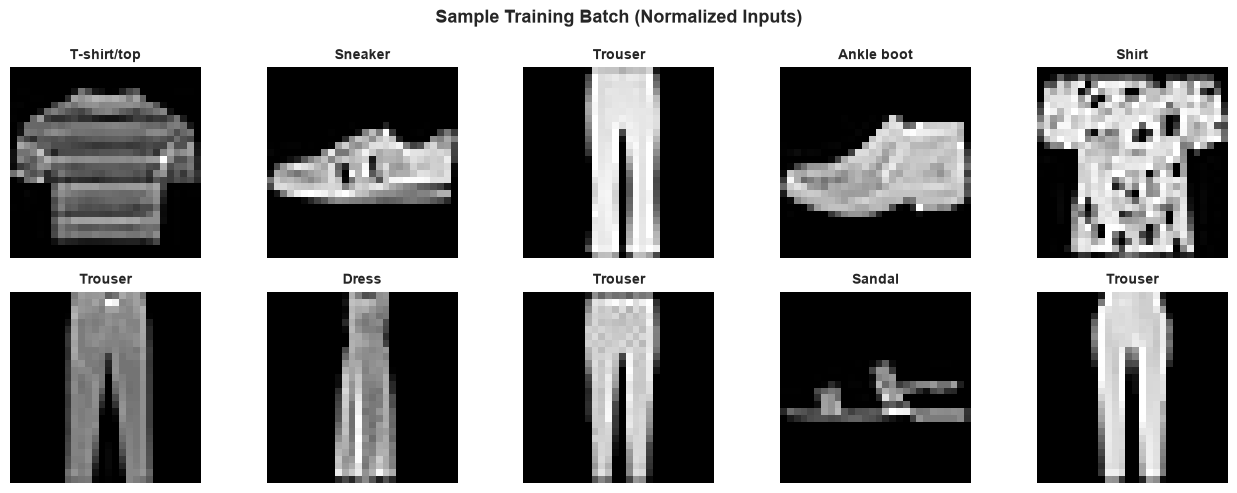

In [4]:
# 2. Hyperparameter Configuration & Data Pipeline
from dataclasses import dataclass

@dataclass
class CNNConfig:
    batch_size: int = 64
    learning_rate: float = 0.001
    weight_decay: float = 1e-4        # L2 Regularization penalty
    dropout_rate: float = 0.30        # Dropout regularization probability
    num_epochs: int = 4               # Number of training epochs
    train_subset_size: int = 8000     # Representative subset for fast, snappy live demonstration
    val_subset_size: int = 2000       # Validation subset

config = CNNConfig()

# Standard Image Transformation Pipeline
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.2860,), (0.3530,)) # Mean and Std of Fashion-MNIST
])

# Load FashionMNIST Datasets
full_train_dataset = datasets.FashionMNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.FashionMNIST(root='./data', train=False, download=True, transform=transform)

# Split into Training and Validation sets with exact seed
indices = list(range(len(full_train_dataset)))
random.Random(42).shuffle(indices)

train_idx = indices[:config.train_subset_size]
val_idx = indices[config.train_subset_size : config.train_subset_size + config.val_subset_size]

train_subset = Subset(full_train_dataset, train_idx)
val_subset = Subset(full_train_dataset, val_idx)

train_loader = DataLoader(train_subset, batch_size=config.batch_size, shuffle=True)
val_loader = DataLoader(val_subset, batch_size=config.batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=config.batch_size, shuffle=False)

class_names = full_train_dataset.classes
print(f"📦 Dataset Partitions Ready:")
print(f"   Train samples:      {len(train_subset):,}")
print(f"   Validation samples: {len(val_subset):,}")
print(f"   Test samples:       {len(test_dataset):,}")
print(f"   Classes (10):       {class_names}")

# Preview a batch of Fashion-MNIST images
images, labels = next(iter(train_loader))
fig, axes = plt.subplots(2, 5, figsize=(13, 5))
for i, ax in enumerate(axes.flat):
    img = images[i].squeeze().numpy() * 0.3530 + 0.2860  # Denormalize for display
    ax.imshow(img, cmap='gray')
    ax.set_title(class_names[labels[i]], fontsize=10, fontweight='bold')
    ax.axis('off')
plt.suptitle('Sample Training Batch (Normalized Inputs)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


---
## Section 4: Building the Modern CNN Architecture (`nn.Module`)

We construct a multi-stage Convolutional Neural Network designed for spatial feature abstraction:

```
[Input: 1 x 28 x 28]
       │
       ▼
[Conv2d(1 -> 32, kernel=3, pad=1)]  ->  [BatchNorm2d]  ->  [ReLU]  ->  [MaxPool2d(2x2)]
       │ (Feature Map: 32 x 14 x 14)
       ▼
[Conv2d(32 -> 64, kernel=3, pad=1)] ->  [BatchNorm2d]  ->  [ReLU]  ->  [MaxPool2d(2x2)]
       │ (Feature Map: 64 x 7 x 7)
       ▼
[Flatten: 64 * 7 * 7 = 3136 features]
       │
       ▼
[Dropout(p=0.3)]  ->  [Linear(3136 -> 128)]  ->  [ReLU]  ->  [Dropout(p=0.2)]
       │
       ▼
[Linear(128 -> 10 Classes)]  ==>  Logits Output
```

### Why Batch Normalization?
Batch Normalization computes mini-batch mean $\mu_B$ and variance $\sigma_B^2$:
$$\hat{x} = \frac{x - \mu_B}{\sqrt{\sigma_B^2 + \epsilon}}, \quad y = \gamma \hat{x} + \beta$$
It stabilizes activation distributions across deep layers, smoothens the loss landscape, and permits higher learning rates.


In [5]:
# 3. Defining the Modular PyTorch CNN Architecture
class ModernFashionCNN(nn.Module):
    def __init__(self, dropout_rate=0.3):
        super(ModernFashionCNN, self).__init__()
        
        # Convolutional Block 1: 1 x 28 x 28 -> 32 x 14 x 14
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)
        
        # Convolutional Block 2: 32 x 14 x 14 -> 64 x 7 x 7
        self.conv2 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)
        
        # Dense Classification Head: 64 * 7 * 7 = 3136
        self.flatten = nn.Flatten()
        self.dropout1 = nn.Dropout(p=dropout_rate)
        self.fc1 = nn.Linear(64 * 7 * 7, 128)
        self.relu3 = nn.ReLU()
        self.dropout2 = nn.Dropout(p=dropout_rate * 0.7)
        self.fc2 = nn.Linear(128, 10)
        
    def forward(self, x):
        # Stage 1: Low-level spatial features (edges, textures)
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu1(x)
        x = self.pool1(x)
        
        # Stage 2: High-level spatial patterns (shapes, object parts)
        x = self.conv2(x)
        x = self.bn2(x)
        x = self.relu2(x)
        x = self.pool2(x)
        
        # Stage 3: Classification head
        x = self.flatten(x)
        x = self.dropout1(x)
        x = self.fc1(x)
        x = self.relu3(x)
        x = self.dropout2(x)
        x = self.fc2(x)
        return x

# Instantiate model and inspect parameter budget
model = ModernFashionCNN(dropout_rate=config.dropout_rate).to(device)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(model)
print(f"\n📊 Model Parameter Budget:")
print(f"   Total Parameters:     {total_params:,}")
print(f"   Trainable Parameters: {trainable_params:,}")
print(f"   (Compare to an equivalent MLP: >1,000,000 parameters for similar depth!)")


ModernFashionCNN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu1): ReLU()
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu2): ReLU()
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (dropout1): Dropout(p=0.3, inplace=False)
  (fc1): Linear(in_features=3136, out_features=128, bias=True)
  (relu3): ReLU()
  (dropout2): Dropout(p=0.21, inplace=False)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)

📊 Model Parameter Budget:
   Total Parameters:     421,834
   Trainable Parameters: 421,834
   (Compare to an equivalent MLP: >1,000,000 para

---
## Section 5: The Canonical Training and Validation Loops Step-by-Step

Every supervised PyTorch deep learning pipeline revolves around two strict execution modes:

### 1. The Training Phase (`model.train()`)
```python
model.train()                         # 1. Enable Dropout & BatchNorm updating
optimizer.zero_grad()                 # 2. Clear accumulated gradients from previous batch!
outputs = model(inputs)               # 3. Forward pass (compute predictions)
loss = criterion(outputs, targets)    # 4. Compute loss (Cross-Entropy)
loss.backward()                       # 5. Backward pass (autograd chain-rule backpropagation)
optimizer.step()                      # 6. Apply parameter update step
```

### 2. The Validation Phase (`model.eval()`)
```python
model.eval()                          # 1. Disable Dropout, freeze BatchNorm running statistics
with torch.no_grad():                 # 2. Disable gradient computation graph (saves memory & CPU)
    outputs = model(inputs)           # 3. Pure forward inference
```


In [6]:
# 4. Defining Clean, Modular Training and Validation Functions
def train_one_epoch(model, dataloader, criterion, optimizer, device):
    """Runs one full training pass over the dataset."""
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    
    for inputs, targets in dataloader:
        inputs, targets = inputs.to(device), targets.to(device)
        
        # 1. Zero out old gradients
        optimizer.zero_grad()
        
        # 2. Forward pass
        outputs = model(inputs)
        loss = criterion(outputs, targets)
        
        # 3. Backward pass (Autograd Backpropagation)
        loss.backward()
        
        # 4. Optimizer update step
        optimizer.step()
        
        # Metric tracking
        running_loss += loss.item() * inputs.size(0)
        _, predicted = outputs.max(1)
        total += targets.size(0)
        correct += predicted.eq(targets).sum().item()
        
    epoch_loss = running_loss / total
    epoch_acc = (correct / total) * 100.0
    return epoch_loss, epoch_acc


def evaluate(model, dataloader, criterion, device):
    """Evaluates model performance without computing gradients."""
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0
    
    with torch.no_grad():
        for inputs, targets in dataloader:
            inputs, targets = inputs.to(device), targets.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            
            running_loss += loss.item() * inputs.size(0)
            _, predicted = outputs.max(1)
            total += targets.size(0)
            correct += predicted.eq(targets).sum().item()
            
    epoch_loss = running_loss / total
    epoch_acc = (correct / total) * 100.0
    return epoch_loss, epoch_acc


---
## Section 6: Live Training Run & Real-Time Performance Curves

Now we initialize the loss function and optimizer, and execute 5 training epochs.
- **Criterion:** `nn.CrossEntropyLoss()` combines `LogSoftmax` and `NLLLoss` into a single numerically stable formula.
- **Optimizer:** `optim.Adam(..., lr=0.001, weight_decay=1e-4)`.


🚀 Starting Live CNN Training for 4 Epochs on cpu...
 Epoch  | Train Loss | Train Acc (%) |  Val Loss  | Val Acc (%) |  Time  
------------------------------------------------------------------------


   1    |   0.7109   |     74.58     |   0.4396   |    84.25    |  12.3 s


   2    |   0.4392   |     84.35     |   0.3890   |    85.55    |  11.8 s


   3    |   0.3748   |     86.49     |   0.4023   |    86.10    |  12.2 s


   4    |   0.3286   |     87.94     |   0.3724   |    87.55    |  11.9 s
------------------------------------------------------------------------
✅ Training Complete in 48.2 seconds! Final Validation Accuracy: 87.55%


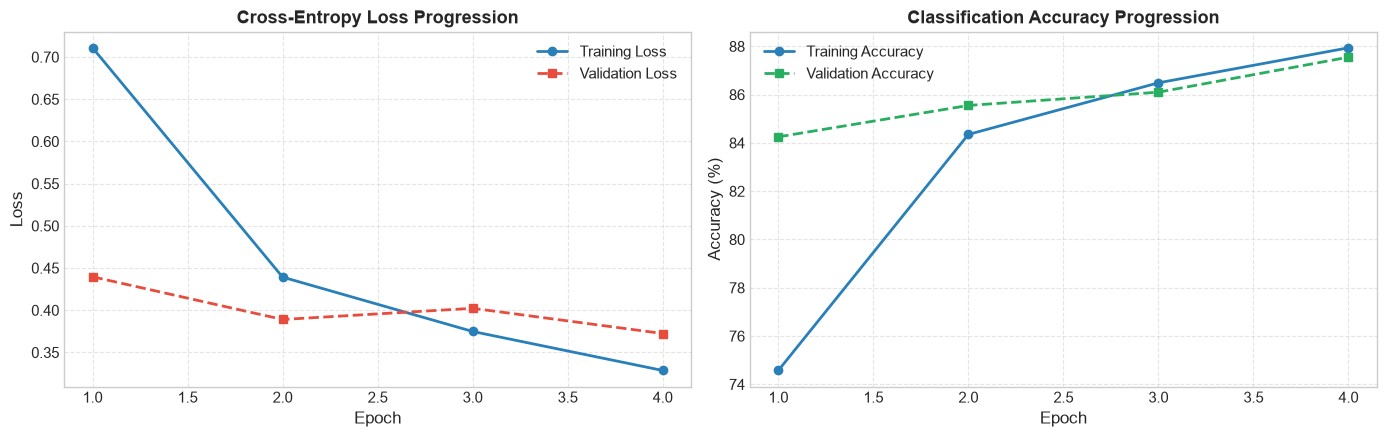

In [7]:
# 5. Live Model Training & Metric Logging
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=config.learning_rate, weight_decay=config.weight_decay)

history = {
    'train_loss': [], 'train_acc': [],
    'val_loss': [],   'val_acc': []
}

print(f"🚀 Starting Live CNN Training for {config.num_epochs} Epochs on {device}...")
print(f"{'Epoch':^7} | {'Train Loss':^10} | {'Train Acc (%)':^13} | {'Val Loss':^10} | {'Val Acc (%)':^11} | {'Time':^7}")
print("-" * 72)

start_time = time.time()
for epoch in range(1, config.num_epochs + 1):
    ep_start = time.time()
    
    train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
    val_loss, val_acc = evaluate(model, val_loader, criterion, device)
    
    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)
    
    ep_duration = time.time() - ep_start
    print(f"{epoch:^7} | {train_loss:^10.4f} | {train_acc:^13.2f} | {val_loss:^10.4f} | {val_acc:^11.2f} | {ep_duration:^6.1f}s")

total_training_time = time.time() - start_time
print("-" * 72)
print(f"✅ Training Complete in {total_training_time:.1f} seconds! Final Validation Accuracy: {history['val_acc'][-1]:.2f}%")

# Plot Learning Curves
fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(14, 4.5))

epochs_range = range(1, config.num_epochs + 1)
ax_loss.plot(epochs_range, history['train_loss'], 'o-', label='Training Loss', color='#2980b9', linewidth=2)
ax_loss.plot(epochs_range, history['val_loss'], 's--', label='Validation Loss', color='#e74c3c', linewidth=2)
ax_loss.set_title('Cross-Entropy Loss Progression', fontweight='bold')
ax_loss.set_xlabel('Epoch')
ax_loss.set_ylabel('Loss')
ax_loss.legend()
ax_loss.grid(True, linestyle='--', alpha=0.5)

ax_acc.plot(epochs_range, history['train_acc'], 'o-', label='Training Accuracy', color='#2980b9', linewidth=2)
ax_acc.plot(epochs_range, history['val_acc'], 's--', label='Validation Accuracy', color='#27ae60', linewidth=2)
ax_acc.set_title('Classification Accuracy Progression', fontweight='bold')
ax_acc.set_xlabel('Epoch')
ax_acc.set_ylabel('Accuracy (%)')
ax_acc.legend()
ax_acc.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


---
## Section 7: Live Demonstration: Overfitting vs. Regularization in Action (Module 3)

### The Generalization Gap:
Overfitting occurs when a model memorizes idiosyncrasies and noise in the training sample rather than learning invariant underlying features.

To demonstrate this live:
1. We train an **Unregularized Model** (Dropout = 0, Weight Decay = 0) on a tiny subset ($N=500$ samples) for 15 epochs.
2. We train a **Regularized Model** (Dropout = 0.4, Weight Decay = 0.01) on the exact same tiny subset.

> **What to observe live:** In the unregularized model, Training Loss drops towards 0 while Validation Loss diverges upwards. In the regularized model, the generalization gap remains tight!


Running fast overfitting comparison (10 epochs on 350 samples)...


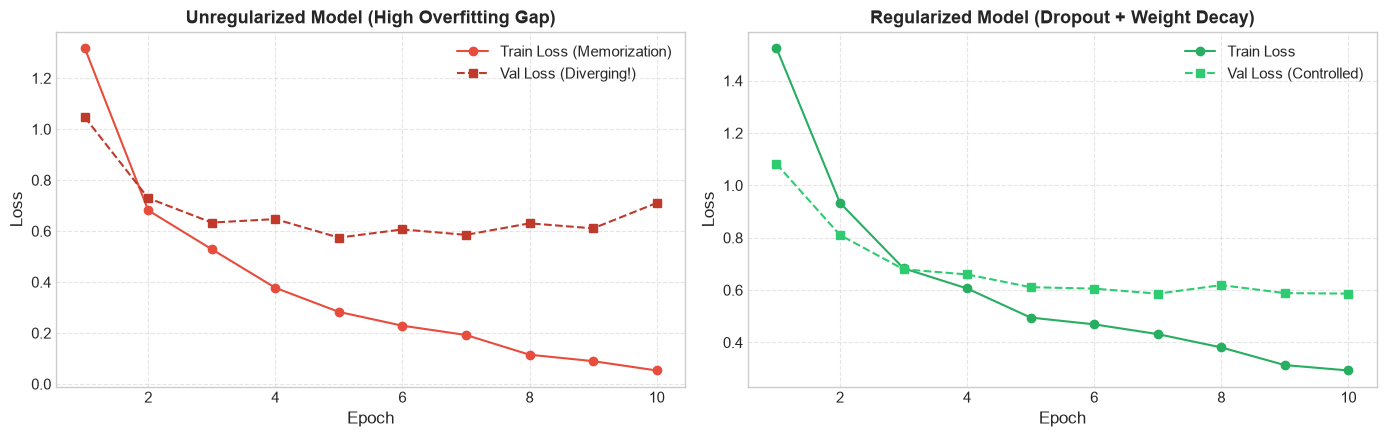

In [8]:
# 6. Live Experiment: Unregularized vs Regularized Model
tiny_train_idx = indices[:500]  # Only 500 samples to induce rapid overfitting
tiny_train_loader = DataLoader(Subset(full_train_dataset, tiny_train_idx), batch_size=32, shuffle=True)

# Model A: Unregularized (No dropout, no L2 weight decay)
model_unreg = ModernFashionCNN(dropout_rate=0.0).to(device)
opt_unreg = optim.Adam(model_unreg.parameters(), lr=0.001, weight_decay=0.0)

# Model B: Regularized (Heavy dropout + Weight decay)
model_reg = ModernFashionCNN(dropout_rate=0.4).to(device)
opt_reg = optim.Adam(model_reg.parameters(), lr=0.001, weight_decay=0.01)

unreg_train_loss, unreg_val_loss = [], []
reg_train_loss, reg_val_loss = [], []

print("Running fast overfitting comparison (10 epochs on 350 samples)...")
for epoch in range(10):
    # Train Model A
    t_loss_a, _ = train_one_epoch(model_unreg, tiny_train_loader, criterion, opt_unreg, device)
    v_loss_a, _ = evaluate(model_unreg, val_loader, criterion, device)
    unreg_train_loss.append(t_loss_a)
    unreg_val_loss.append(v_loss_a)
    
    # Train Model B
    t_loss_b, _ = train_one_epoch(model_reg, tiny_train_loader, criterion, opt_reg, device)
    v_loss_b, _ = evaluate(model_reg, val_loader, criterion, device)
    reg_train_loss.append(t_loss_b)
    reg_val_loss.append(v_loss_b)

# Plotting the Overfitting Gap
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))

epochs = range(1, 11)
ax1.plot(epochs, unreg_train_loss, 'o-', color='#e74c3c', label='Train Loss (Memorization)')
ax1.plot(epochs, unreg_val_loss, 's--', color='#c0392b', label='Val Loss (Diverging!)')
ax1.set_title('Unregularized Model (High Overfitting Gap)', fontweight='bold')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.legend()
ax1.grid(True, linestyle='--', alpha=0.5)

ax2.plot(epochs, reg_train_loss, 'o-', color='#27ae60', label='Train Loss')
ax2.plot(epochs, reg_val_loss, 's--', color='#2ecc71', label='Val Loss (Controlled)')
ax2.set_title('Regularized Model (Dropout + Weight Decay)', fontweight='bold')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss')
ax2.legend()
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


---
## Section 8: Model Evaluation, Diagnostics & Interpretability

A responsible ML engineer does not rely on global accuracy alone. In this section we:
1. Evaluate on the **unseen Test Set (10,000 samples)**.
2. Generate the **Confusion Matrix Heatmap** to detect pairwise class confusions (e.g., Shirt vs. T-shirt).
3. **Inspect Learned Feature Maps:** We peer inside the convolutional layers of our trained model to visualize the 32 feature maps produced by the first conv layer!


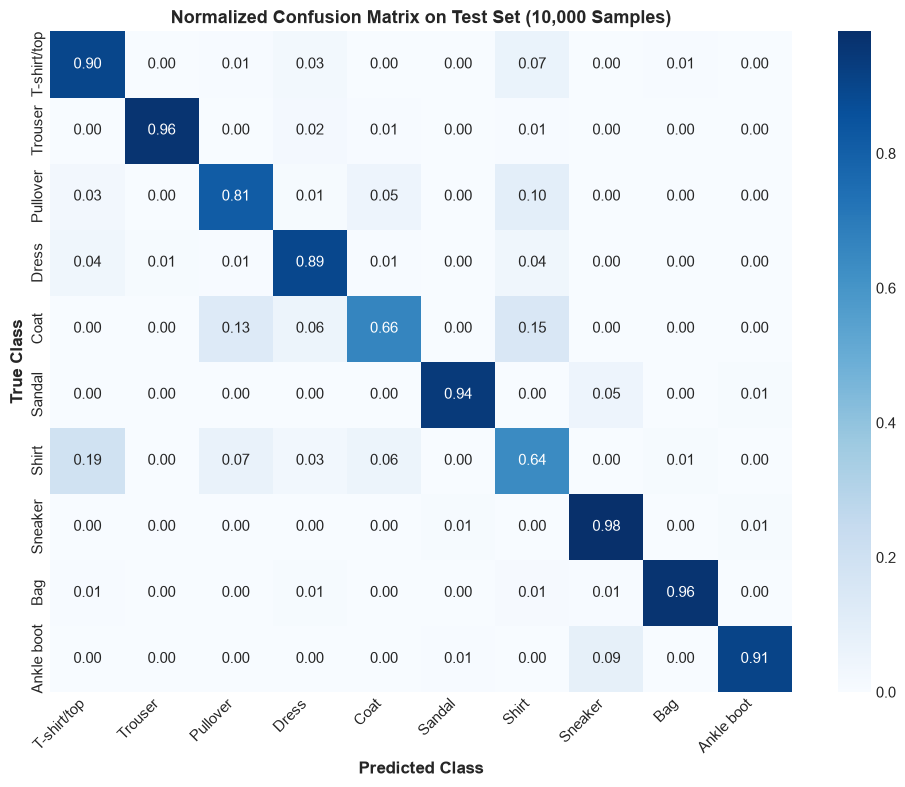


📋 Detailed Classification Report:
              precision    recall  f1-score   support

 T-shirt/top      0.768     0.897     0.827      1000
     Trouser      0.983     0.964     0.973      1000
    Pullover      0.796     0.814     0.805      1000
       Dress      0.853     0.893     0.872      1000
        Coat      0.849     0.662     0.744      1000
      Sandal      0.982     0.939     0.960      1000
       Shirt      0.628     0.637     0.632      1000
     Sneaker      0.874     0.981     0.924      1000
         Bag      0.978     0.963     0.970      1000
  Ankle boot      0.982     0.905     0.942      1000

    accuracy                          0.866     10000
   macro avg      0.869     0.865     0.865     10000
weighted avg      0.869     0.866     0.865     10000



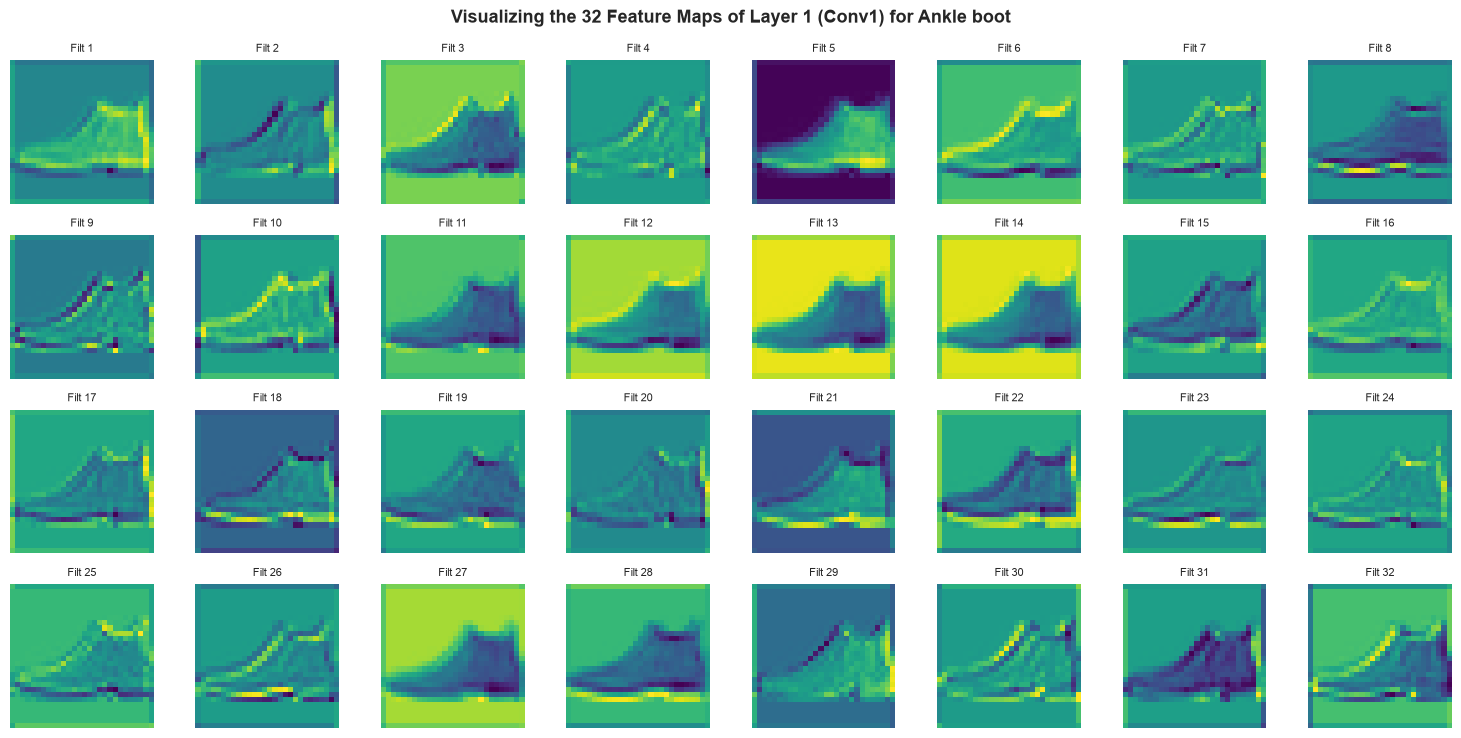

In [9]:
# 7. Test Set Evaluation & Confusion Matrix
model.eval()
all_preds = []
all_targets = []

with torch.no_grad():
    for inputs, targets in test_loader:
        inputs = inputs.to(device)
        outputs = model(inputs)
        _, preds = outputs.max(1)
        all_preds.extend(preds.cpu().numpy())
        all_targets.extend(targets.numpy())

all_preds = np.array(all_preds)
all_targets = np.array(all_targets)

# Confusion Matrix Heatmap
cm = confusion_matrix(all_targets, all_preds)
cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

plt.figure(figsize=(10, 8))
sns.heatmap(cm_normalized, annot=True, fmt='.2f', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Normalized Confusion Matrix on Test Set (10,000 Samples)', fontsize=13, fontweight='bold')
plt.xlabel('Predicted Class', fontweight='bold')
plt.ylabel('True Class', fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Print Precision, Recall, F1
print("\n📋 Detailed Classification Report:")
print(classification_report(all_targets, all_preds, target_names=class_names, digits=3))

# Feature Map Visualization: What did Conv1 learn?
sample_test_img, sample_test_lbl = test_dataset[0]  # Ankle boot
input_tensor = sample_test_img.unsqueeze(0).to(device) # Shape: [1, 1, 28, 28]

with torch.no_grad():
    feature_maps = model.conv1(input_tensor) # Shape: [1, 32, 28, 28]
feature_maps = feature_maps.squeeze(0).cpu().numpy()

fig, axes = plt.subplots(4, 8, figsize=(15, 7.5))
for i, ax in enumerate(axes.flat):
    ax.imshow(feature_maps[i], cmap='viridis')
    ax.set_title(f'Filt {i+1}', fontsize=8)
    ax.axis('off')
plt.suptitle(f'Visualizing the 32 Feature Maps of Layer 1 (Conv1) for {class_names[sample_test_lbl]}', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


---
## Section 9: Syllabus Touchpoint - Transfer Learning in Computer Vision (Module 12)

In industrial practice, training deep networks from scratch on small datasets is inefficient. **Transfer Learning** leverages rich representations learned by models trained on millions of images (e.g., ImageNet):

### Two Transfer Learning Paradigms:
1. **Feature Extraction:**
   - Freeze all convolutional backbone weights: `param.requires_grad = False`.
   - Replace and train **only** the final classification head for the custom domain.
   - Extremely fast, requires minimal data, zero risk of catastrophic forgetting.
2. **Fine-Tuning:**
   - Unfreeze top convolutional layers and train with a very small learning rate (e.g., $\alpha = 10^{-5}$) along with the new classifier.


In [10]:
# 8. Practical Transfer Learning Architecture Blueprint
print("Transfer Learning Model Adaptation Blueprint:")

# Conceptual setup using torchvision pre-trained models
pretrained_model = models.mobilenet_v3_small(weights=None) # Architecture blueprint

# Step 1: Freeze all feature extractor parameters
for param in pretrained_model.features.parameters():
    param.requires_grad = False

# Step 2: Replace the classifier head for 10 classes
in_features = pretrained_model.classifier[3].in_features
pretrained_model.classifier[3] = nn.Linear(in_features, 10)

# Verify trainable vs frozen parameters
trainable = sum(p.numel() for p in pretrained_model.parameters() if p.requires_grad)
frozen = sum(p.numel() for p in pretrained_model.parameters() if not p.requires_grad)

print(f"   Frozen Parameters (Backbone):    {frozen:,} (Weights locked)")
print(f"   Trainable Parameters (New Head): {trainable:,} (Only these update!)")
print("✅ Ready for instant deployment and fast fine-tuning on domain-specific datasets!")


Transfer Learning Model Adaptation Blueprint:
   Frozen Parameters (Backbone):    927,008 (Weights locked)
   Trainable Parameters (New Head): 601,098 (Only these update!)
✅ Ready for instant deployment and fast fine-tuning on domain-specific datasets!
